# H3: error budget of the per-epoch positions

For Gaia stars, each epoch's corrected offset is its error relative to Gaia. Per band and correction stage:
- **systematic DCR** -- RMS of the binned median offset along the parallactic direction in cells of colour x airmass
  (the signal DCR targets);
- robust scatter **along** and **across** the parallactic direction, and **per axis** = sqrt((along^2 + across^2)/2);
- **removed** by each step = sqrt(before^2 - after^2) of the per-axis scatter.

Then the floor vs magnitude: per-axis scatter of the fully corrected offsets, the median statistical error, and the
implied systematic error sqrt(scatter^2 - stat^2), to compare with sigma_sys = 20 mas (`py_files/error_model.py`).
Clean stars only (pm_quality == 0 equivalent) unless stated. Data: all measured epochs of Gaia stars in a random
fraction of bricks of every processed slice (`dcr_fit.load_stage_sample`). Writes `writeup/tables/error_budget.tex`
and `writeup/plots/error_floor_vs_mag.pdf`. Rerun after the pipeline rerun.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
from py_files.error_model import SIGMA_SYS_MAS
ps.apply()
DEGREES = ['000-063']
BRICK_FRACTION = 0.05
PLOTS, TABLES = '../writeup/plots/', '../writeup/tables/'
CACHE = f"/pscratch/sd/n/nelfalou/legacypm-catalogue-v2/combined/stage_sample_{'_'.join(DEGREES)}_{BRICK_FRACTION}.npz"
if os.path.exists(CACHE):
    S = dict(np.load(CACHE))
else:
    S = dcr_fit.load_stage_sample(DEGREES, brick_fraction=BRICK_FRACTION, max_sigma_mas=1e6)   # all measured epochs
    np.savez(CACHE, **S)
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
STAGES = [('raw', 'none'), ('dcr', '+ DCR'), ('rm', '+ CCD maps'), ('lm', '+ lateral colour')]
BANDS = ['g', 'r', 'i', 'z']
C_EDGES = np.linspace(-2, 3, 26); T_EDGES = np.array([0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.3])
bright = S['sig_stat'] < 10
print(f"{len(S['band']):,} epochs; {bright.sum():,} with sigma < 10 mas; clean stars: {100 * S['clean'].mean():.0f}% of epochs")

25,285,774 epochs; 18,611,662 with sigma < 10 mas; clean stars: 73% of epochs


In [2]:
# Error budget table: clean stars, sigma < 10 mas epochs
rows = []
for b in BANDS:
    m = (S['band'] == b) & S['clean'] & bright & np.isfinite(S['c_rel'])
    prev = None
    for st, label in STAGES:
        cells = dcr_fit.binned_2d(S['c_rel'][m], S['tanz'][m], S[f'par_{st}'][m], C_EDGES, T_EDGES)
        w = 1 / cells[3]**2
        sysdcr = np.sqrt(np.sum(w * cells[2]**2) / np.sum(w))
        al, ac = rs(S[f'par_{st}'][m]), rs(S[f'perp_{st}'][m])
        pa = np.sqrt((al**2 + ac**2) / 2)
        removed = np.sign(prev - pa) * np.sqrt(abs(prev**2 - pa**2)) if prev is not None else np.nan   # < 0: step adds scatter
        rows.append((b, label, m.sum(), sysdcr, al, ac, pa, removed))
        prev = pa
print(f"{'band':4s} {'stage':18s} {'N':>9s} {'sys DCR':>8s} {'along':>7s} {'across':>7s} {'per axis':>9s} {'removed':>8s}  (mas)")
for b, label, n, sd, al, ac, pa, rm in rows:
    print(f"{b:4s} {label:18s} {n:9,d} {sd:8.2f} {al:7.2f} {ac:7.2f} {pa:9.2f} {rm:8.2f}")
# LaTeX table for the paper
lines = [r'\begin{table}', r'\centering',
         r'\caption{Error budget of the per-epoch positions of clean Gaia stars with statistical errors below 10\,mas, after each '
         r'correction step: RMS of the systematic DCR signal (binned medians along the parallactic direction in cells of '
         r'colour and airmass), robust scatter along and across the parallactic direction and per axis, and the per-axis '
         r'scatter removed by each step ($\sqrt{\sigma_{\rm before}^2 - \sigma_{\rm after}^2}$; negative if the step adds scatter). '
         r'All in mas.}', r'\label{tab:error_budget}', r'\begin{tabular}{llrrrrr}', r'\hline',
         r'Band & Correction & DCR signal & Along & Across & Per axis & Removed \\', r'\hline']
for b, label, n, sd, al, ac, pa, rm in rows:
    lines.append(f"${b}$ & {label} & {sd:.1f} & {al:.1f} & {ac:.1f} & {pa:.1f} & {'--' if np.isnan(rm) else f'{rm:.1f}'} \\\\")
    if label == STAGES[-1][1] and b != BANDS[-1]:
        lines.append(r'\hline')
lines += [r'\hline', r'\end{tabular}', r'\end{table}']
os.makedirs(TABLES, exist_ok=True)
open(TABLES + 'error_budget.tex', 'w').write('\n'.join(lines) + '\n')
print('wrote', TABLES + 'error_budget.tex')

band stage                      N  sys DCR   along  across  per axis  removed  (mas)
g    none               2,550,205    18.66   27.07   13.69     21.45      nan
g    + DCR              2,550,205     1.81   16.10   13.69     14.94    15.39
g    + CCD maps         2,550,205     1.62   13.53   11.09     12.37     8.39
g    + lateral colour   2,550,205     1.73   12.86   10.54     11.76     3.83
r    none               4,060,115     6.22   15.52   12.59     14.13      nan
r    + DCR              4,060,115     0.76   13.73   12.59     13.17     5.11
r    + CCD maps         4,060,115     0.64   11.30    9.99     10.67     7.73
r    + lateral colour   4,060,115     0.67   11.25    9.93     10.61     1.08
i    none               3,687,320     3.15   13.38   12.23     12.82      nan
i    + DCR              3,687,320     0.49   12.78   12.23     12.51     2.79
i    + CCD maps         3,687,320     0.43   10.12    9.32      9.73     7.86
i    + lateral colour   3,687,320     0.44   10.11    9.3

implied systematic, clean stars, by G bin: {14.25: 29.3, 14.75: 20.6, 15.25: 14.9, 15.75: 11.5, 16.25: 11.8, 16.75: 11.7, 17.25: 11.6, 17.75: 11.5, 18.25: 11.9, 18.75: 12.7, 19.25: 14.0, 19.75: 15.4, 20.25: 18.2, 20.75: 24.8, 21.25: 32.7}


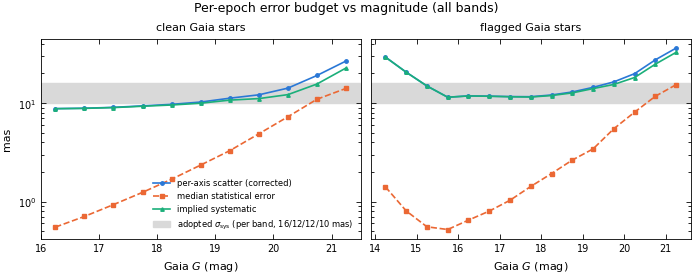

In [3]:
# Floor vs magnitude: per-axis scatter of fully corrected offsets of Gaia stars, median statistical error, and the
# implied systematic error sqrt(scatter^2 - stat^2); all bands together, clean and flagged stars separately.
gb = np.arange(14, 21.51, 0.5); gc = 0.5 * (gb[1:] + gb[:-1])
pa_lm = np.sqrt((S['par_lm']**2 + S['perp_lm']**2) / 2)
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.8), sharey=True, constrained_layout=True)
for ax, sel, title in [(axes[0], S['clean'], 'clean Gaia stars'), (axes[1], ~S['clean'], 'flagged Gaia stars')]:
    sc, st, sy = [], [], []
    for a, b in zip(gb, gb[1:]):
        m = sel & (S['G'] > a) & (S['G'] <= b)
        if m.sum() < 500:
            sc.append(np.nan); st.append(np.nan); sy.append(np.nan); continue
        s_ = np.sqrt((rs(S['par_lm'][m])**2 + rs(S['perp_lm'][m])**2) / 2)
        e_ = np.median(S['sig_stat'][m])
        sc.append(s_); st.append(e_); sy.append(np.sqrt(max(s_**2 - e_**2, 0)))
    for k, (y, label, ls) in enumerate([(sc, 'per-axis scatter (corrected)', '-'), (st, 'median statistical error', '--'),
                                        (sy, 'implied systematic', '-')]):
        ax.semilogy(gc, y, ls=ls, marker=ps.MARKERS[k], ms=2.5, color=ps.SERIES[k], label=label)
    ax.axhspan(min(SIGMA_SYS_MAS.values()), max(SIGMA_SYS_MAS.values()), color='0.85', zorder=0,
               label=r'adopted $\sigma_{\rm sys}$ (per band, ' + '/'.join(f'{v:.0f}' for v in SIGMA_SYS_MAS.values()) + ' mas)')
    ax.set_title(title); ax.set_xlabel('Gaia $G$ (mag)')
axes[0].set_ylabel('mas'); axes[0].legend(fontsize=6)
fig.suptitle('Per-epoch error budget vs magnitude (all bands)')
plt.savefig(PLOTS + 'error_floor_vs_mag.pdf')
print('implied systematic, clean stars, by G bin:', dict(zip(np.round(gc, 2), np.round(sy, 1))))